# EDA: Digikala product reviews and product catalog

Exploratory data analysis of two tables collected from Digikala (an Iranian e-commerce marketplace).

| Table | File | Rows | Columns | One row is |
|---|---|---|---|---|
| Comments | `comments.parquet` | 6,156,289 | 15 | one user comment on a product |
| Products | `products.parquet` | 1,283,496 (948,352 unique ids) | 12 | one catalog entry |

**Purpose.** Understand the structure, quality problems and distributions of the data *before* cleaning and modelling. Every rule in `cleaning.ipynb` is justified by a finding documented in this notebook (see the table in the last section).

**How to run.** Put the two parquet files next to this notebook and run all cells from top to bottom. Requirements: Python 3.12, pandas 3.x (the default `str` dtype is assumed), numpy, matplotlib, seaborn, scikit-learn, pyarrow. Section 9 (bigrams over all 6M texts) is by far the slowest part; everything else is fast. Tables (`.csv`) and figures (`.png`) are saved to `eda_output/`.

**How to read.** Every section starts with a note: *what* the code does, *what was found* (numbers are from the full-data run) and *what it means for cleaning*. Figures contain no Persian labels on purpose (matplotlib does not shape Persian text); Persian values appear in tables only.

## Data dictionary

**Comments (`comments.parquet`)**

| Column | Meaning | Notes |
|---|---|---|
| `id` | comment id | not fully unique, see section 4 |
| `product_id` | product the comment belongs to | foreign key to `products.id`, no orphans |
| `title` | short headline written by the user | 46.6% missing |
| `body` | main comment text (Persian) | 0.01% missing, median 29 characters |
| `created_at` | Jalali date string, e.g. `23 شهریور 1402` | cannot be parsed by `pd.to_datetime` |
| `rate` | rating given with the comment | not a clean 1-5 score, see section 5 |
| `recommendation_status` | `recommended` / `not_recommended` / `no_idea` / missing | 14.5% missing |
| `is_buyer` | commenter bought the product | 95.1% true |
| `advantages`, `disadvantages` | optional pros/cons | stringified Python lists such as `['a', 'b']` |
| `likes`, `dislikes` | votes received by the comment | heavy-tailed |
| `seller_title`, `seller_code` | seller of the product | about 4.9% missing |
| `true_to_size_rate` | fit feedback (`fit`, `small`, `big`, `tooSmall`, `tooBig`) | only clothing, 98.5% missing |

**Products (`products.parquet`)**

| Column | Meaning | Notes |
|---|---|---|
| `id` | product id | repeated, see section 4 |
| `title_fa` | Persian product title | |
| `Rate` | average rating on a 0-100 scale | 0 when the product has no ratings |
| `Rate_cnt` | number of ratings | 0 for 62% of products |
| `Category1`, `Category2` | category levels | `Category2` 16.4% missing; labels overlap |
| `Brand` | brand name | `متفرقه` ("miscellaneous") for 55.9% of products |
| `Price` | integer price | currency unit is not stated in the data (likely Rial); 174 zeros |
| `Seller` | seller name | |
| `Is_Fake` | Digikala's counterfeit flag | 5.0% true |
| `min_price_last_month` | lowest price in the last month | 0 for 94.2% of products |
| `sub_category` | one of 6 English labels | `clothe`, `book & stationary & art`, `beauty`, `toys and kids`, `rural goods`, `travel` |

## Conventions used in the code
- `df_comm` / `df_prod`: the raw tables. `prod`: products with one row per id (built in section 4).
- Helpers: `save_table(df, name)` writes a CSV to `eda_output/` and displays it; `save_fig(name)` saves and shows the current figure; `with_share(counts, total)` adds a percent column.
- Texts are never modified in this notebook except for converting placeholder strings to missing values (section 2).

## Version history of this notebook
1. Original single-cell script. It crashed on the shape print (a tuple formatted with `:,`), and had several latent problems (category dtype with `fillna`, boolean column in `describe`, repeated `describe`).
2. Split into one cell per task and fixed those bugs.
3. Redesigned after the first full run: placeholder `"nan"` strings, Jalali dates, histograms with a fake spike at the 99th percentile, unparsed advantage/disadvantage lists, duplicate product ids, and many new analyses (rating, engagement, per-product and per-seller, sub-category views).
4. This version: documentation added; the `rate` plot was unreadable (178 distinct values) and is now grouped; `seller_title` placeholders are converted too (the top-sellers table had `nan` as its second-largest seller).

In [1]:
import ast
from collections import Counter
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

COMMENTS_PATH = Path("comments.parquet")
PRODUCTS_PATH = Path("products.parquet")
OUTPUT_DIR = Path("eda_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TOP_K = 20
COLOR = "#397A67"


def save_table(df, name):
    df.to_csv(OUTPUT_DIR / f"{name}.csv", encoding="utf-8-sig")
    display(df)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=140)
    plt.show()
    plt.close()


def with_share(counts, total=None):
    total = counts.sum() if total is None else total
    return pd.DataFrame({"count": counts, "percent": (counts / total * 100).round(2)})

## 1. Load data

**What.** Reads both parquet files completely (no sampling) and previews three rows of each.

**Found.** 6,156,289 comments x 15 columns and 1,283,496 product rows x 12 columns. The preview already shows two problems that sections 2 and 6 deal with: missing values written as the string `nan`, and pros/cons stored as strings that look like Python lists.

In [2]:
for path in (COMMENTS_PATH, PRODUCTS_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing input file: {path.resolve()}")

df_comm = pd.read_parquet(COMMENTS_PATH)
df_prod = pd.read_parquet(PRODUCTS_PATH)

print(f"Comments: {df_comm.shape[0]:,} rows x {df_comm.shape[1]} cols")
print(f"Products: {df_prod.shape[0]:,} rows x {df_prod.shape[1]} cols")
display(df_comm.head(3))
display(df_prod.head(3))

Comments: 6,156,289 rows x 15 cols
Products: 1,283,496 rows x 12 cols


,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,nan,nan,0,0,دیجی‌کالا,5A52N,nan
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,nan
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,26 مرداد 1401,0.0,recommended,True,3331597,nan,nan,0,0,آرالیا بیوتی,ADM47,nan


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,NaN,متفرقه,634800,سلامت ساز راد,False,0,beauty
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,NaN,متفرقه,818800,مهر افزون,False,0,beauty
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,NaN,متفرقه,920000,یانگوم,False,0,beauty


## 2. Clean placeholder values

**What.** Converts the placeholder strings `""`, `"nan"` and `"[]"` into real missing values in `title`, `body`, `advantages`, `disadvantages`, `recommendation_status`, `true_to_size_rate`, `seller_title` and `seller_code`.

**Why.** The data was exported with missing values written as the literal text `nan`. Without this step `isna()` reports 0% missing everywhere, and the length histograms show a huge fake spike at 3 characters (the length of "nan"). This step only makes the EDA numbers truthful; the cleaning notebook repeats it for both tables.

**Note.** `seller_title` and `seller_code` were added in the latest version, after the top-sellers table showed `nan` as the second-largest "seller" (302,181 comments).

In [3]:
TEXT_COLS = ["title", "body", "advantages", "disadvantages"]
STRING_COLS = TEXT_COLS + ["recommendation_status", "true_to_size_rate", "seller_title", "seller_code"]
PLACEHOLDERS = ["", "nan", "[]"]

for col in STRING_COLS:
    df_comm[col] = df_comm[col].mask(df_comm[col].str.strip().isin(PLACEHOLDERS))

## 3. Missing values

**What.** Missing count, percent and dtype for every column of both tables.

**Found (comments, after section 2).**

| Column | Missing |
|---|---|
| `true_to_size_rate` | 98.53% (only filled for clothing and shoes) |
| `disadvantages` | 93.30% |
| `advantages` | 88.50% |
| `title` | 46.56% |
| `recommendation_status` | 14.53% |
| `seller_title` | about 4.9% (302,181 comments); re-run to see the exact figure |
| `body` | 0.01% (637 rows) |

All other comment columns are complete. In the products table only `Category2` has missing values (16.37% of rows, 19.12% of unique products).

**Meaning.** Missingness is informative here: an empty `advantages` simply means the user skipped an optional field. These columns must not be imputed. Only comments without `body` lack the main text.

In [ ]:
def missing_report(df):
    return pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "dtype": df.dtypes.astype(str),
    }).sort_values("missing_percent", ascending=False)


print("Comments")
save_table(missing_report(df_comm), "missing_comments")
print("Products")
save_table(missing_report(df_prod), "missing_products")

## 4. Duplicates and referential integrity

**What.** Counts exact duplicate rows and repeated ids in both tables, shows an example of a repeated product id, checks that every commented product exists in the catalog, and builds `prod` (one row per product id) for all later product analyses.

**Found.**
- Comments: 1,318 exact duplicate rows and 3,229 repeated ids, so about 1,900 extra rows share an id with another row without being identical (probably the same comment captured twice with different like counts; this is a hypothesis).
- Products: 323,129 exact duplicate rows and 335,144 repeated ids, so about 12,000 extra rows share an id but differ in at least one column. The catalog has **948,352 unique products**, not 1,283,496.
- Referential integrity is perfect: no commented product id is missing from the catalog. 331,599 products (35.0% of the catalog) have at least one comment.

**Meaning.** Exact duplicates are safe to drop. Conflicting duplicates need an explicit, documented rule (see `cleaning.ipynb`, step 2). `prod = df_prod.drop_duplicates("id")` keeps the first row per id and is only an EDA convenience.

In [5]:
print(f"Comment rows fully duplicated: {df_comm.duplicated().sum():,}")
print(f"Comment ids duplicated:        {df_comm['id'].duplicated().sum():,}")
print(f"Product rows fully duplicated: {df_prod.duplicated().sum():,}")
print(f"Product ids duplicated:        {df_prod['id'].duplicated().sum():,}")

duplicated_ids = df_prod.loc[df_prod["id"].duplicated(keep=False), "id"]
if not duplicated_ids.empty:
    print("\nExample of a product id that appears more than once:")
    display(df_prod[df_prod["id"] == duplicated_ids.iloc[0]])

n_catalog = df_prod["id"].nunique()
commented_ids = pd.Series(df_comm["product_id"].unique())
print(f"\nUnique products in catalog: {n_catalog:,}")
print(f"Unique products with comments: {len(commented_ids):,} ({len(commented_ids) / n_catalog:.1%} of catalog)")
print(f"Commented product ids missing from catalog: {(~commented_ids.isin(df_prod['id'])).sum():,}")

prod = df_prod.drop_duplicates("id").copy()
print(f"\nProducts kept for analysis (one row per id): {len(prod):,}")

Comment rows fully duplicated: 1,318
Comment ids duplicated:        3,229
Product rows fully duplicated: 323,129
Product ids duplicated:        335,144

Example of a product id that appears more than once:


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
25,1452939,آبسلانگ مدل 1002 بسته 30 عددی,76,166,آبسلانگ,NaN,متفرقه,245000,سلامت ساز راد,False,0,beauty
26,1452939,آبسلانگ مدل 1002 بسته 30 عددی,76,166,آبسلانگ,NaN,متفرقه,245000,سلامت ساز راد,False,0,beauty



Unique products in catalog: 948,352
Unique products with comments: 331,599 (35.0% of catalog)
Commented product ids missing from catalog: 0

Products kept for analysis (one row per id): 948,352


## 5. Recommendation status, rating and engagement

**What.** Distribution of the label-like columns (`recommendation_status`, `rate`) and of the engagement columns (`is_buyer`, `likes`, `dislikes`, `true_to_size_rate`).

**Found.**
- `recommendation_status`: recommended 67.62%, missing 14.53%, no_idea 9.65%, not_recommended 8.20%. Strongly imbalanced; negative comments are rare.
- `rate` is **not** a clean 1-5 star score. It has 178 distinct values: whole numbers dominate (5.0 is 38.97%, 0 is 8.59%), but fractional values (0.05 to 4.9) exist and one row has the impossible value 2500. A bar per distinct value was unreadable in the first run, so rates are now grouped.
- `rate == 0` behaves like "no rating", not like a zero score: 80.5% of those comments are *recommended*, whereas tiny positive rates such as 0.05 are 83.5% *not recommended*. The cleaning notebook therefore treats 0 as missing (an assumption that can be switched off).
- `is_buyer` is true for 95.1% of comments.
- 19.4% of comments have at least one like (max 1,136) and 4.7% at least one dislike (max 336). Heavy-tailed: raw likes are a poor quality filter.
- `true_to_size_rate` exists for 1.47% of comments: fit 70,622, small 9,096, big 5,626, tooSmall 3,438, tooBig 1,991.

**Meaning.** Keep missing `recommendation_status` as its own state; fix or null impossible `rate` values; handle class imbalance at modelling time.

,count,percent
recommendation_status,,
recommended,4162839,67.62
missing,894426,14.53
no_idea,594121,9.65
not_recommended,504903,8.20


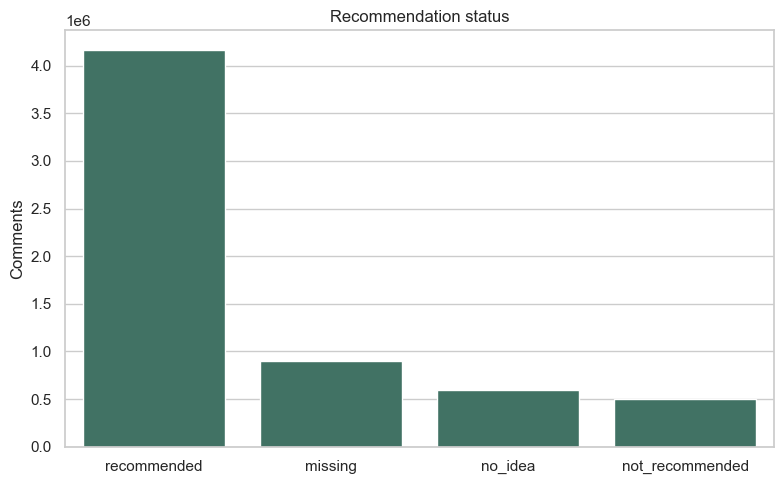

In [6]:
status = df_comm["recommendation_status"].fillna("missing").value_counts()
save_table(with_share(status), "recommendation_status")

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=status.index.astype(str), y=status.values, color=COLOR)
ax.set(title="Recommendation status", xlabel="", ylabel="Comments")
save_fig("recommendation_status")

In [ ]:
rate = df_comm["rate"]
print(f"Distinct rate values: {rate.nunique():,}")
print(f"Whole-number rates: {(rate % 1 == 0).mean():.1%}")
print(f"Rates outside [0, 5]: {((rate < 0) | (rate > 5)).sum():,}")

rate_group = pd.cut(
    rate,
    bins=[-np.inf, 0, 1, 2, 3, 4, np.nextafter(5, 0), 5, np.inf],
    labels=["0", "(0,1]", "(1,2]", "(2,3]", "(3,4]", "(4,5)", "5", ">5 (invalid)"],
)
group_counts = rate_group.value_counts().sort_index()
save_table(with_share(group_counts), "comment_rate_groups")

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=group_counts.index.astype(str), y=group_counts.values, color=COLOR)
ax.set(title="Comment rate (grouped)", xlabel="rate", ylabel="Comments")
save_fig("comment_rate_groups")

status_by_rate = pd.crosstab(
    rate_group, df_comm["recommendation_status"].fillna("missing"), normalize="index"
).mul(100).round(1)
print("Recommendation status by rate group (row %)")
save_table(status_by_rate, "status_by_rate_group")

In [8]:
print(f"Comments from buyers: {df_comm['is_buyer'].mean():.1%}")
print(f"Comments with at least one like: {(df_comm['likes'] > 0).mean():.1%}")
print(f"Comments with at least one dislike: {(df_comm['dislikes'] > 0).mean():.1%}")

save_table(
    df_comm[["likes", "dislikes"]].describe(percentiles=[.5, .9, .99]).T.round(2),
    "likes_dislikes_stats",
)

print("true_to_size_rate")
save_table(with_share(df_comm["true_to_size_rate"].fillna("missing").value_counts().head(10)), "true_to_size_rate")

Comments from buyers: 95.1%
Comments with at least one like: 19.4%
Comments with at least one dislike: 4.7%


,count,mean,std,min,50%,90%,99%,max
likes,6156289.0,0.45,2.29,0.0,0.0,1.0,7.0,1136.0
dislikes,6156289.0,0.09,0.83,0.0,0.0,0.0,2.0,336.0


true_to_size_rate


,count,percent
true_to_size_rate,,
missing,6065516,98.53
fit,70622,1.15
small,9096,0.15
big,5626,0.09
tooSmall,3438,0.06
tooBig,1991,0.03


## 6. Text fields

**What.** How often each text field is filled, length distributions of `body` and `title`, and the number of items in `advantages` / `disadvantages`.

**Found.**
- Filled: `body` 99.99%, `title` 53.44%, `advantages` 11.50%, `disadvantages` 6.70%.
- `body` length (non-missing): median 29, mean 48.4, p90 106, p99 297, max 4,000 characters. Roughly 280k comments (about 4.5%) are shorter than 5 characters.
- `title` length: median 9, p99 56, max 1,149.
- `advantages` / `disadvantages` are stringified lists. About 708k comments have at least one advantage (1.34M items in total) and about 412k at least one disadvantage (533k items). Most lists have a single item. 99 and 136 lists contain only blank items.
- The length histograms ignore missing texts and cut at the 99th percentile (shown in the plot title) instead of clipping, which in the first version created a fake spike at the last bin.

**Meaning.** Texts are short; very short bodies are noise for text models and will be flagged. Lists must be parsed before any text analysis (the raw strings are Python `repr` output and can contain escaped characters such as `\u200c`).

In [9]:
fill_rate = df_comm[TEXT_COLS].notna().mean().mul(100).round(2).to_frame("filled_percent")
save_table(fill_rate, "text_fill_rate")

,filled_percent
title,53.44
body,99.99
advantages,11.50
disadvantages,6.70


body: 6,155,652 non-missing texts, 99th percentile = 297 chars (61,019 longer texts not shown)


,body_length
count,6155652.0
mean,48.4
std,64.4
min,1.0
50%,29.0
90%,106.0
95%,152.0
99%,297.0
max,4000.0


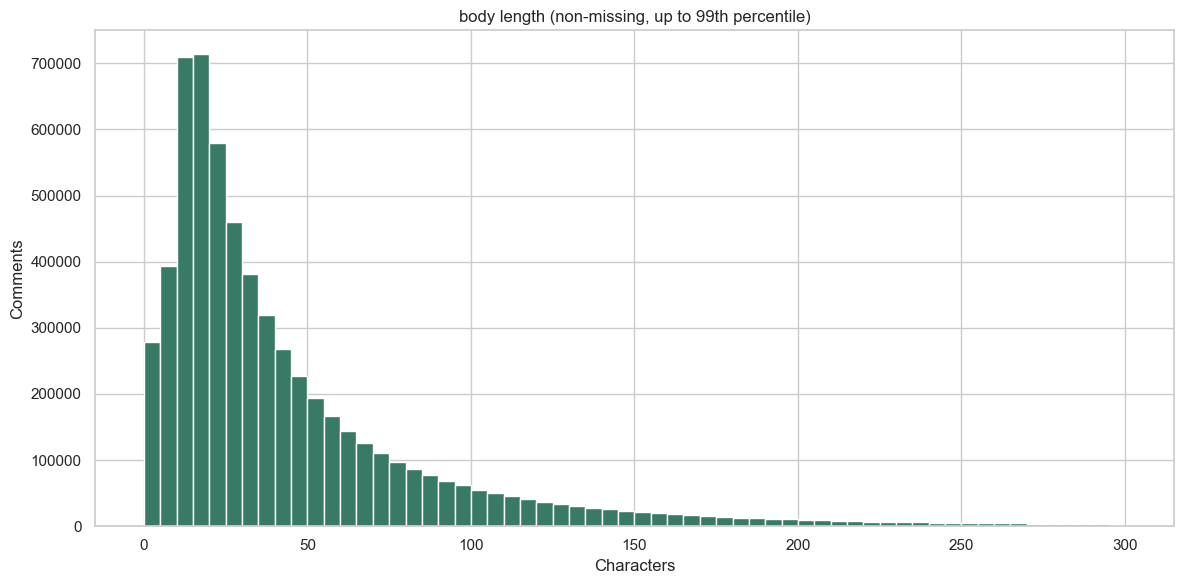

title: 3,289,874 non-missing texts, 99th percentile = 56 chars (31,875 longer texts not shown)


,title_length
count,3289874.0
mean,11.6
std,11.6
min,1.0
50%,9.0
90%,22.0
95%,30.0
99%,56.0
max,1149.0


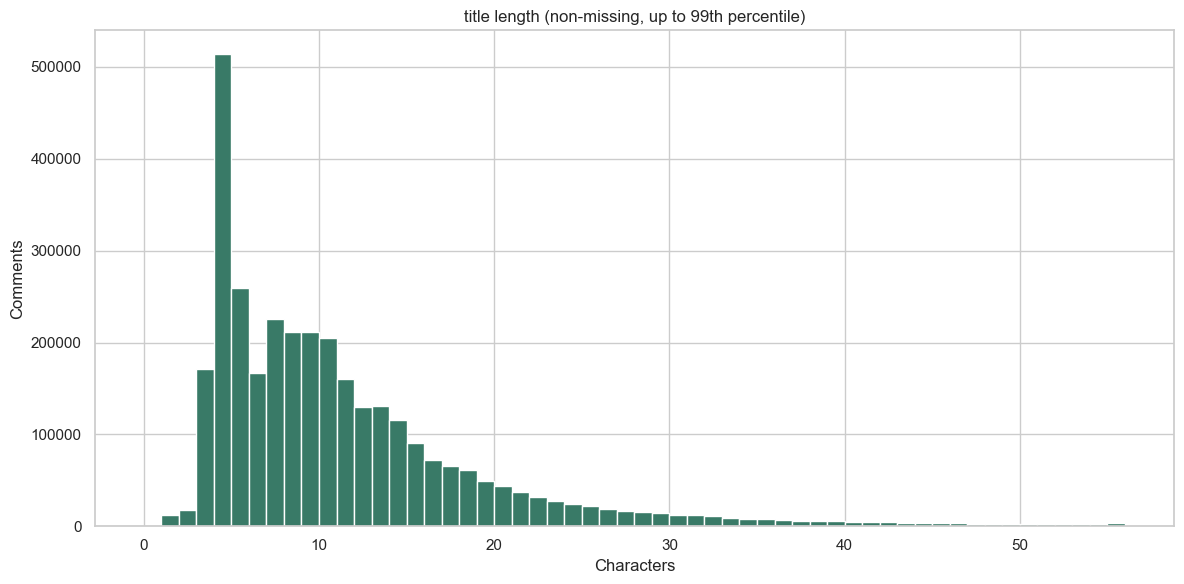

In [10]:
def plot_length_hist(series, name, binwidth):
    lengths = series.dropna().str.len()
    cap = lengths.quantile(0.99)
    shown = lengths[lengths <= cap]
    print(f"{name}: {len(lengths):,} non-missing texts, 99th percentile = {cap:.0f} chars "
          f"({len(lengths) - len(shown):,} longer texts not shown)")
    save_table(lengths.describe(percentiles=[.5, .9, .95, .99]).round(1).to_frame(f"{name}_length"),
               f"length_stats_{name}")

    plt.figure()
    plt.hist(shown, bins=np.arange(0, cap + binwidth, binwidth), color=COLOR)
    plt.title(f"{name} length (non-missing, up to 99th percentile)")
    plt.xlabel("Characters")
    plt.ylabel("Comments")
    save_fig(f"length_{name}")


plot_length_hist(df_comm["body"], "body", binwidth=5)
plot_length_hist(df_comm["title"], "title", binwidth=1)

,advantages,disadvantages
items_per_comment,,
0,99,136
1,347995,330460
2,180803,53777
3,117823,19753
4,41072,5765
5+,20413,2381


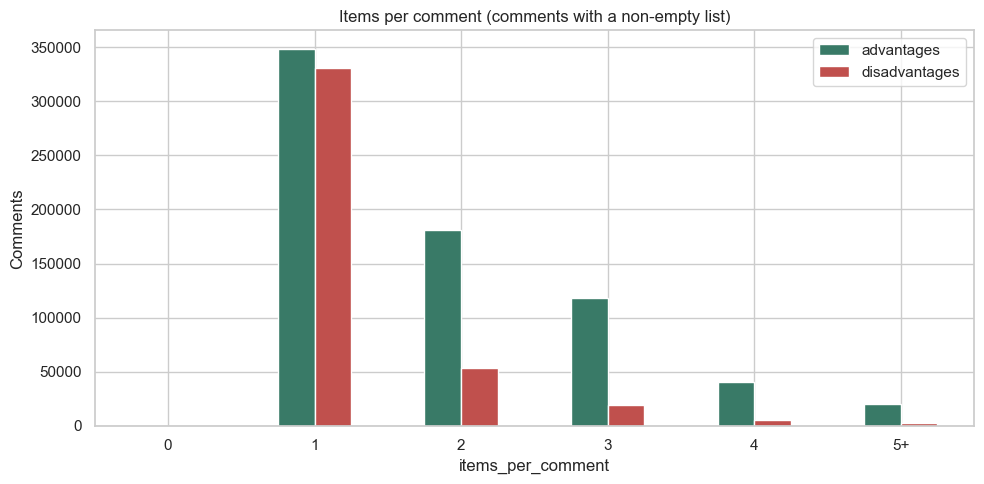

In [11]:
def parse_list(text):
    try:
        parsed = ast.literal_eval(text)
    except (ValueError, SyntaxError):
        return [text]
    if not isinstance(parsed, (list, tuple)):
        parsed = [parsed]
    return [str(item) for item in parsed if str(item).strip()]


parsed_lists = {col: df_comm[col].dropna().map(parse_list) for col in ["advantages", "disadvantages"]}

items_df = pd.DataFrame({
    col: lists.map(len).clip(upper=5).value_counts().sort_index()
    for col, lists in parsed_lists.items()
}).fillna(0).astype(int)
items_df.index = [f"{i}+" if i == 5 else str(i) for i in items_df.index]
items_df.index.name = "items_per_comment"
save_table(items_df, "list_items_per_comment")

items_df.plot.bar(figsize=(10, 5), color=[COLOR, "#C0504D"], rot=0)
plt.title("Items per comment (comments with a non-empty list)")
plt.ylabel("Comments")
save_fig("list_items_per_comment")

## 7. Comments over time (Jalali calendar)

**What.** Extracts year and month from the Jalali date string and counts comments per month and per year. `created_at` looks like `23 شهریور 1402`, so `pd.to_datetime` cannot parse it (the first version reported 100% invalid dates, which was misleading). Persian and Arabic digits are normalised first.

**Found.**
- All 6,156,289 dates parse; 0 are unparsed.
- The series starts in 1395 and ends during 1402; the final month is incomplete (the curve drops).
- Comments per Jalali year: 1395 3,575; 1396 6,357; 1397 16,693; 1398 138,645; 1399 684,321; 1400 1,253,484; 1401 2,165,894; 1402 1,887,320 (partial year).
- 65.8% of all comments are from 1401-1402; before 1398 there are fewer than 3%.

**Meaning.** The data is strongly skewed to recent years. Time-based train/test splits should account for this and should not use the incomplete last month. The cleaning notebook adds a Gregorian `created_date`.

Unparsed dates: 0 (0.00%)
Comments per Jalali year


,count,percent
year,,
1395,3575,0.06
1396,6357,0.10
1397,16693,0.27
1398,138645,2.25
1399,684321,11.12
1400,1253484,20.36
1401,2165894,35.18
1402,1887320,30.66


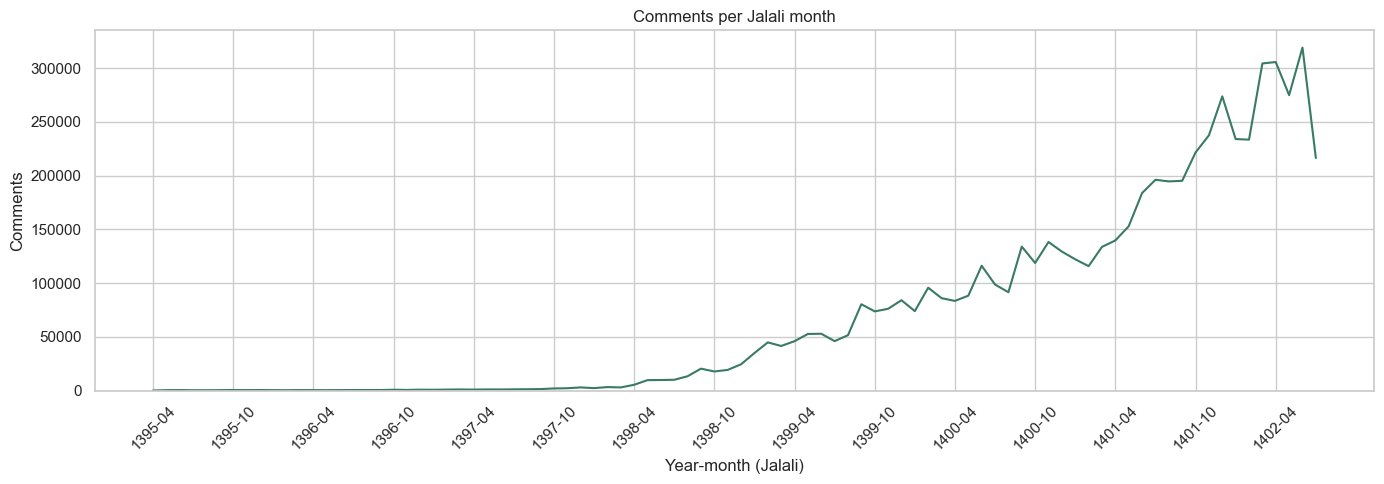

In [12]:
JALALI_MONTHS = {
    "فروردین": 1, "اردیبهشت": 2, "خرداد": 3, "تیر": 4, "مرداد": 5, "شهریور": 6,
    "مهر": 7, "آبان": 8, "آذر": 9, "دی": 10, "بهمن": 11, "اسفند": 12,
}
CHAR_MAP = str.maketrans({
    **{c: str(i) for i, c in enumerate("۰۱۲۳۴۵۶۷۸۹")},
    **{c: str(i) for i, c in enumerate("٠١٢٣٤٥٦٧٨٩")},
    "ي": "ی",
    "ك": "ک",
})

raw_dates = df_comm["created_at"].str.translate(CHAR_MAP)
parts = raw_dates.str.extract(r"(?P<day>\d{1,2})\s+(?P<month_name>\S+)\s+(?P<year>\d{4})")
jalali = pd.DataFrame({
    "year": pd.to_numeric(parts["year"], errors="coerce"),
    "month": parts["month_name"].map(JALALI_MONTHS),
})
valid = jalali["year"].notna() & jalali["month"].notna()

print(f"Unparsed dates: {(~valid).sum():,} ({(~valid).mean():.2%})")
if (~valid).any():
    display(df_comm.loc[~valid, "created_at"].value_counts().head(10).to_frame())

year_month = jalali.loc[valid, "year"].astype(int) * 100 + jalali.loc[valid, "month"].astype(int)
months = [y * 100 + m for y in range(year_month.min() // 100, year_month.max() // 100 + 1) for m in range(1, 13)]
months = [v for v in months if year_month.min() <= v <= year_month.max()]
monthly = year_month.value_counts().reindex(months, fill_value=0)
monthly.index = [f"{v // 100}-{v % 100:02d}" for v in monthly.index]
monthly.name = "comments"
monthly.index.name = "jalali_year_month"

yearly = jalali.loc[valid, "year"].astype(int).value_counts().sort_index()
print("Comments per Jalali year")
save_table(with_share(yearly), "comments_per_year")

monthly.to_csv(OUTPUT_DIR / "comments_per_month.csv", encoding="utf-8-sig")
plt.figure(figsize=(14, 5))
plt.plot(range(len(monthly)), monthly.values, color=COLOR)
ticks = range(0, len(monthly), 6)
plt.xticks(ticks, [monthly.index[i] for i in ticks], rotation=45)
plt.ylim(bottom=0)
plt.title("Comments per Jalali month")
plt.xlabel("Year-month (Jalali)")
plt.ylabel("Comments")
save_fig("comments_per_month")

## 8. Comments per product and per seller

**What.** Distribution of the number of comments per product (log-log histogram) and the most active sellers.

**Found.**
- Median 4 comments per product, p90 46, p99 200, and a maximum of exactly 400. A hard maximum at a round number suggests the collection stopped at 400 comments per product, so popular products are truncated (hypothesis).
- Very long tail: a few products and sellers account for a large share of comments. In the first run `دیجی‌کالا` (Digikala itself) had 5.67% of all comments and the placeholder `nan` was the second-largest "seller" (4.91%); the latter is fixed in section 2.

**Meaning.** Per-product statistics from comments are unreliable for popular products; compare with `Rate_cnt` in the catalog (up to 30,438 ratings).

In [ ]:
per_product = df_comm["product_id"].value_counts()
save_table(per_product.describe(percentiles=[.5, .9, .99]).round(1).to_frame("comments_per_product"),
           "comments_per_product_stats")

plt.figure()
plt.hist(per_product, bins=np.logspace(0, np.log10(per_product.max()), 50), color=COLOR)
plt.xscale("log")
plt.yscale("log")
plt.title("Comments per product (log-log)")
plt.xlabel("Comments")
plt.ylabel("Products")
save_fig("comments_per_product")

print(f"Top {TOP_K} sellers by comments ({df_comm['seller_title'].nunique():,} sellers in total)")
save_table(with_share(df_comm["seller_title"].value_counts().head(TOP_K), total=len(df_comm)), "top_sellers")

## 9. Most frequent bigrams

**What.** The 20 most frequent two-word sequences in `body`, `advantages`, `disadvantages` and in the `body` of `not_recommended` comments, over the full corpus. The token pattern keeps the zero-width non-joiner (`\u200c`) inside words, so "می‌تونست" stays one token. List columns are parsed first and every item is one document.

**Found.**
- `body`: dominated by generic satisfaction phrases (`خوب بود`, `عالی بود`, `خیلی خوبه`, `راضی بودم`) and platform names (`دیجی کالا`).
- `advantages`: `قیمت مناسب` (60,323), `بسته بندی`, `جنس خوب`, `کیفیت خوب`.
- `disadvantages`: `قیمت بالا` (11,398), `بی کیفیت`, `کیفیت پایین`, `ماندگاری کم`, `حجم کم`.
- `body` of `not_recommended`: `بی کیفیت` (23,368), `مرجوع کردم` (19,362), `خوب نیست`, `خوب نبود`, `توصیه نمیکنم`.
- Bigrams overlap by construction ("بسته بندی خوب" gives both `بسته بندی` and `بندی خوب`).

**Meaning.** Price, packaging and quality are the main themes. Function words (`نسبت به`, `از این`, `با این`) show up; a stop-word list is needed for any word-level analysis. No spelling normalisation was applied here, which the cleaning notebook does.

In [14]:
def top_bigrams(texts, top_k=TOP_K, chunk_size=50_000):
    texts = texts.dropna()
    totals = Counter()
    for chunk_no, start in enumerate(range(0, len(texts), chunk_size), 1):
        chunk = texts.iloc[start:start + chunk_size]
        vectorizer = CountVectorizer(
            ngram_range=(2, 2),
            token_pattern=r"(?u)[\w\u200c]{2,}",
            dtype=np.int32,
        )
        try:
            matrix = vectorizer.fit_transform(chunk)
        except ValueError:
            continue
        counts = np.asarray(matrix.sum(axis=0)).ravel().tolist()
        totals.update(dict(zip(vectorizer.get_feature_names_out(), counts)))
        if chunk_no % 20 == 0:
            print(f"  {min(start + chunk_size, len(texts)):,}/{len(texts):,} texts")
    return pd.DataFrame(totals.most_common(top_k), columns=["bigram", "count"]).set_index("bigram")


bigram_inputs = {
    "body": df_comm["body"],
    "advantages": parsed_lists["advantages"].explode().dropna(),
    "disadvantages": parsed_lists["disadvantages"].explode().dropna(),
}
for col, texts in bigram_inputs.items():
    print(f"\nTop {TOP_K} bigrams: {col} ({len(texts):,} texts)")
    save_table(top_bigrams(texts), f"top_bigrams_{col}")

not_recommended = df_comm.loc[df_comm["recommendation_status"] == "not_recommended", "body"]
print(f"\nTop {TOP_K} bigrams: body of not_recommended comments ({len(not_recommended):,} texts)")
save_table(top_bigrams(not_recommended), "top_bigrams_body_not_recommended")


Top 20 bigrams: body (6,156,289 texts)
  1,000,000/6,155,652 texts
  2,000,000/6,155,652 texts
  3,000,000/6,155,652 texts
  4,000,000/6,155,652 texts
  5,000,000/6,155,652 texts
  6,000,000/6,155,652 texts


,count
bigram,
خوب بود,442478
نسبت به,231952
عالی بود,185125
خوبی داره,167693
خیلی خوبه,166627
خیلی خوب,149305
دیجی کالا,134982
در کل,122345
به قیمت,117971



Top 20 bigrams: advantages (1,341,258 texts)
  1,000,000/1,341,258 texts


,count
bigram,
قیمت مناسب,60323
بسته بندی,30438
جنس خوب,28373
کیفیت خوب,26175
با کیفیت,20118
کیفیت مناسب,13212
کیفیت عالی,12766
نسبت به,10499
بوی خوب,9572



Top 20 bigrams: disadvantages (533,463 texts)


,count
bigram,
قیمت بالا,11398
بی کیفیت,7359
بسته بندی,7114
کیفیت پایین,4965
نسبت به,4279
ماندگاری کم,2868
حجم کم,2773
شده بود,2366
بعد از,2160



Top 20 bigrams: body of not_recommended comments (504,903 texts)


,count
bigram,
بی کیفیت,23368
مرجوع کردم,19362
دیجی کالا,16773
سفارش دادم,15198
خوب نیست,13996
شده بود,12838
خوب نبود,12423
بعد از,11865
اصلا خوب,11532


## 10. Products: price

**What.** Price statistics, a log-scale histogram of positive prices and price by `sub_category`.

**Found.**
- Median 1,700,000; mean 9.1M; p90 15.5M; p99 120.8M; max 8.5 billion. 174 products have price 0.
- Strongly right-skewed (log-normal-like), so a log scale is required. The histogram looks jagged because prices cluster at round numbers.
- Median price by sub-category: `clothe` 2.7M, `travel` 1.68M, `toys and kids` and `rural goods` 1.6M, `beauty` 1.12M, `book & stationary & art` 0.97M.

**Meaning.** Treat price 0 as missing, work with log-price, and flag (do not drop) extreme values.

Products with price 0: 174


,price
count,9.483520e+05
mean,9.145403e+06
std,5.187011e+07
min,0.000000e+00
10%,4.000000e+05
50%,1.700000e+06
90%,1.550000e+07
99%,1.208350e+08
max,8.499990e+09


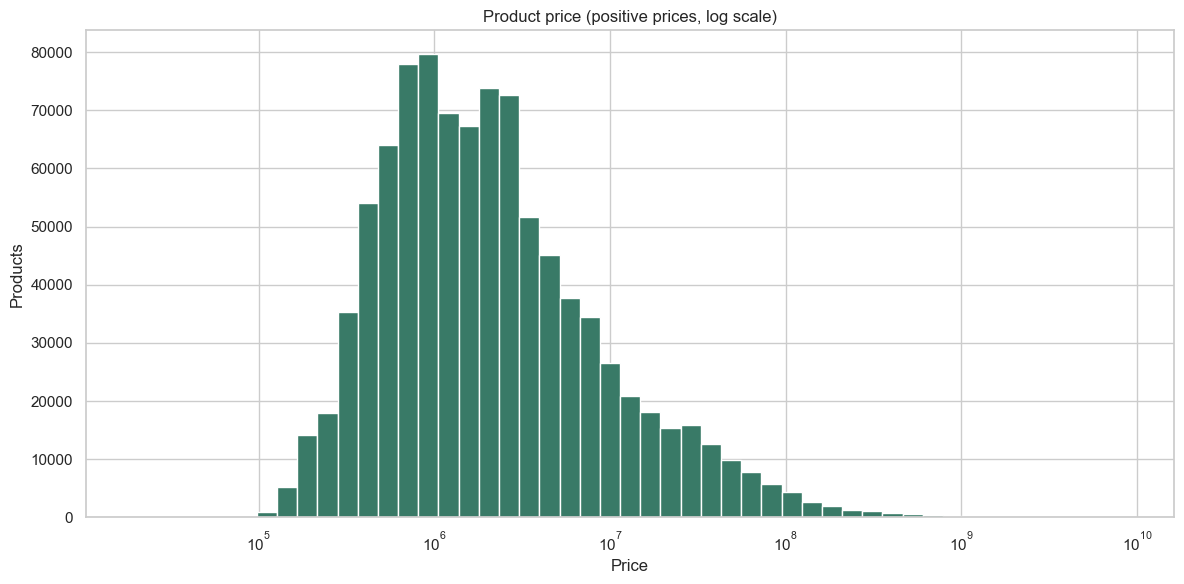

Price by sub_category (positive prices)


,count,median,mean,max
sub_category,,,,
beauty,116504,1120000.0,4850450.0,3430000000
book & stationary & art,274275,974000.0,10244965.0,8499990000
clothe,442551,2700000.0,10250430.0,7645500000
rural goods,24113,1600000.0,6516642.0,1000000000
toys and kids,66989,1600000.0,5824054.0,1202000000
travel,23746,1680000.0,9029123.0,1599000000


In [15]:
prices = prod["Price"]
print(f"Products with price 0: {(prices == 0).sum():,}")
save_table(prices.describe(percentiles=[.1, .5, .9, .99]).round(0).to_frame("price"), "price_stats")

positive = prices[prices > 0]
plt.figure()
plt.hist(positive, bins=np.logspace(np.log10(positive.min()), np.log10(positive.max()), 50), color=COLOR)
plt.xscale("log")
plt.title("Product price (positive prices, log scale)")
plt.xlabel("Price")
plt.ylabel("Products")
save_fig("price_distribution")

print("Price by sub_category (positive prices)")
price_by_sub = prod[prod["Price"] > 0].groupby("sub_category")["Price"].agg(["count", "median", "mean", "max"]).round(0)
save_table(price_by_sub, "price_by_sub_category")

## 11. Products: brands and categories

**What.** Top brands and categories, the share of products vs the share of comments per `sub_category`, and recommendation status per `sub_category`.

**Found.**
- `Brand`: 8,961 unique values. The generic `متفرقه` ("miscellaneous") covers **55.9%** of products; the next brand has 1.45%.
- `Category1`: 228 unique values; `Category2`: 602, missing for 19.12% of unique products. Labels overlap (`اکسسوری زنانه`, `اکسسوری مردانه`, `اکسسوری زنانه و مردانه`) and have spelling variants (zero-width joiner vs space, e.g. `برس‌ها` / `برس ها`).
- `sub_category` (6 values): `clothe` holds 46.7% of products but only 24.0% of comments (3.3 comments per product); `beauty` holds 12.3% of products but 36.3% of comments (19.2 per product).
- `not_recommended` share is highest in `clothe` (11.2%) and lowest in `book & stationary & art` (5.2%).

**Meaning.** Brand is uninformative for more than half of the products; category labels need spelling normalisation (hierarchy problems are not fixed automatically). Comment volume is dominated by beauty products, so results aggregated over all comments mostly describe beauty.

In [16]:
for col in ["Brand", "Category1", "Category2", "sub_category"]:
    counts = prod[col].fillna("missing").value_counts()
    print(f"\n{col}: {counts.size:,} unique values (including missing). Top {TOP_K}:")
    save_table(with_share(counts.head(TOP_K), total=len(prod)), f"top_{col.lower()}")


Brand: 8,961 unique values (including missing). Top 20:


,count,percent
Brand,,
متفرقه,530051,55.89
لیردا,13798,1.45
الن نار,12308,1.30
خندالو,7687,0.81
کرابو,7295,0.77
اچ اند ام,7075,0.75
ترمه ۱,6534,0.69
اسمارا,5933,0.63
27,5220,0.55



Category1: 228 unique values (including missing). Top 20:


,count,percent
Category1,,
لباس زنانه,77928,8.22
اکسسوری زنانه,57514,6.06
لباس مردانه,55970,5.90
اکسسوری زنانه و مردانه,52644,5.55
اسباب بازی,42645,4.50
دخترانه,35260,3.72
زیورآلات طلا زنانه,32903,3.47
اکسسوری مردانه,32337,3.41
کتاب چاپی غیر فارسی,31792,3.35



Category2: 602 unique values (including missing). Top 20:


,count,percent
Category2,,
missing,181346,19.12
دفتر,26458,2.79
زیورآلات زنانه و مردانه,21925,2.31
لباس دخترانه,21781,2.30
فکری و آموزشی,20612,2.17
زیورآلات زنانه,18045,1.90
تی شرت مردانه,18044,1.90
لباس پسرانه,17797,1.88
زیورآلات نقره زنانه,15872,1.67



sub_category: 6 unique values (including missing). Top 20:


,count,percent
sub_category,,
clothe,442577,46.67
book & stationary & art,274326,28.93
beauty,116545,12.29
toys and kids,67011,7.07
rural goods,24116,2.54
travel,23777,2.51


,products,comments,comments_per_product
sub_category,,,
beauty,116545,2236510,19.19
book & stationary & art,274326,1512717,5.51
clothe,442577,1475878,3.33
rural goods,24116,150362,6.23
toys and kids,67011,618325,9.23
travel,23777,162497,6.83


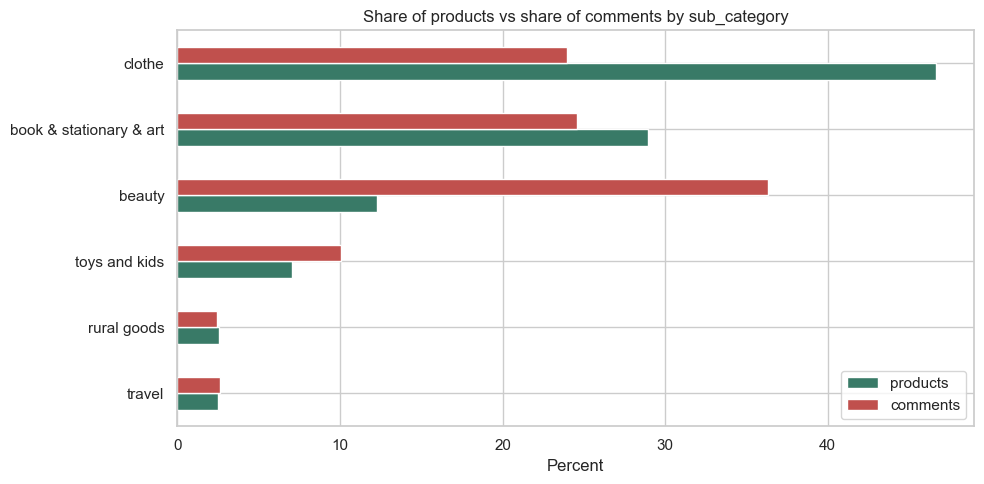

Recommendation status by sub_category (row %)


recommendation_status,missing,no_idea,not_recommended,recommended
sub_category,,,,
beauty,14.2,10.3,7.9,67.6
book & stationary & art,13.7,7.6,5.2,73.6
clothe,14.4,11.1,11.2,63.3
rural goods,21.1,8.3,8.8,61.8
toys and kids,16.5,9.0,9.3,65.3
travel,14.4,9.9,9.2,66.4


In [17]:
df_comm["sub_category"] = df_comm["product_id"].map(prod.set_index("id")["sub_category"])

by_sub = pd.DataFrame({
    "products": prod["sub_category"].value_counts(),
    "comments": df_comm["sub_category"].value_counts(),
})
by_sub["comments_per_product"] = (by_sub["comments"] / by_sub["products"]).round(2)
save_table(by_sub, "products_and_comments_by_sub_category")

shares = by_sub[["products", "comments"]].div(by_sub[["products", "comments"]].sum()).mul(100)
shares.sort_values("products").plot.barh(figsize=(10, 5), color=[COLOR, "#C0504D"])
plt.title("Share of products vs share of comments by sub_category")
plt.xlabel("Percent")
plt.ylabel("")
save_fig("sub_category_shares")

print("Recommendation status by sub_category (row %)")
status_by_sub = pd.crosstab(
    df_comm["sub_category"], df_comm["recommendation_status"].fillna("missing"), normalize="index"
).mul(100).round(1)
save_table(status_by_sub, "status_by_sub_category")

## 12. Products: rating, fake flag and price history

`Rate` is 0 whenever a product has no ratings, so rating statistics use rated products only.

**Found.**
- Only 38.1% of products (360,945) have at least one rating. Among them `Rate` has mean 79.9 and median 80 (scale 0-100).
- `Rate` clusters at multiples of 20 for products with few ratings (an average of 1-5 stars scaled by 20, hypothesis) and about a quarter of rated products have exactly one rating, so `Rate` is noisy for small `Rate_cnt`. `Rate_cnt` median 4, p99 817, max 30,438.
- `Is_Fake` is true for 5.03% of products (47,662) but is concentrated: `clothe` 9.94%, `travel` 7.56%, all other sub-categories below 1%.
- `min_price_last_month` is 0 for 94.2% of products; only 55,182 (5.8%) have a value (median 1.48M).

**Meaning.** Set `Rate` to missing when `Rate_cnt == 0`, treat `min_price_last_month == 0` as missing, and use a minimum `Rate_cnt` (for example 5) whenever `Rate` is used as a feature or label.

Products with at least one rating: 360,945 (38.1%)


,count,mean,std,min,10%,50%,90%,99%,max
Rate,360945.0,79.9,15.9,0.0,60.0,80.0,100.0,100.0,100.0
Rate_cnt,360945.0,46.5,305.4,1.0,1.0,4.0,58.0,817.0,30438.0


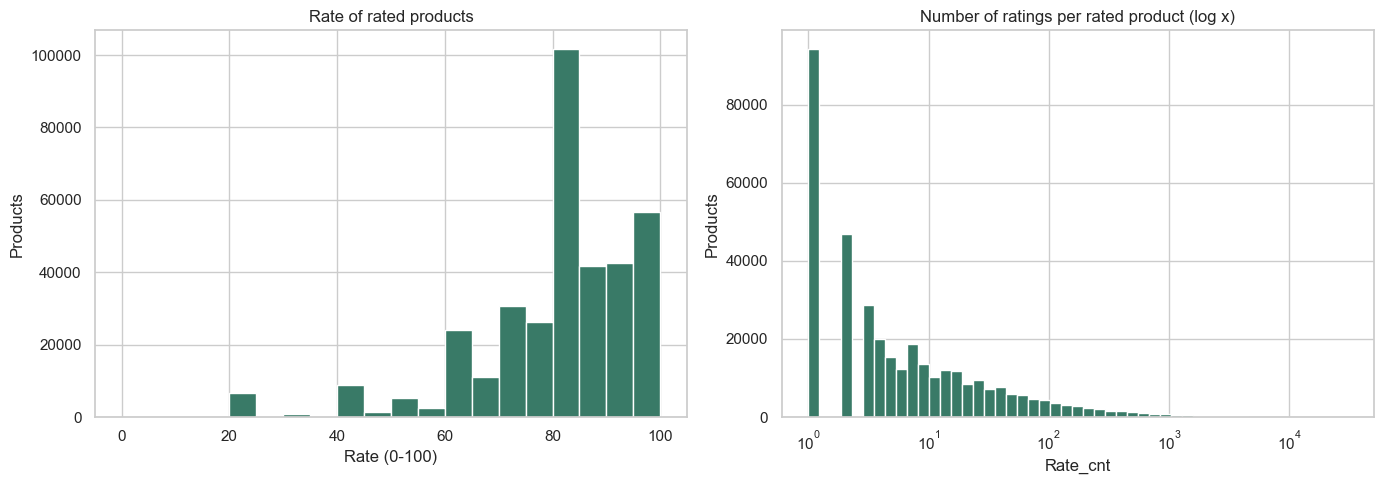

In [18]:
rated = prod[prod["Rate_cnt"] > 0]
print(f"Products with at least one rating: {len(rated):,} ({len(rated) / len(prod):.1%})")
save_table(rated[["Rate", "Rate_cnt"]].describe(percentiles=[.1, .5, .9, .99]).T.round(1), "rated_products_stats")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(rated["Rate"], bins=np.arange(0, 105, 5), color=COLOR)
axes[0].set(title="Rate of rated products", xlabel="Rate (0-100)", ylabel="Products")
axes[1].hist(rated["Rate_cnt"], bins=np.logspace(0, np.log10(rated["Rate_cnt"].max()), 50), color=COLOR)
axes[1].set(title="Number of ratings per rated product (log x)", xlabel="Rate_cnt", ylabel="Products", xscale="log")
save_fig("rated_products")

In [19]:
save_table(with_share(prod["Is_Fake"].value_counts()), "is_fake_counts")

fake_by_sub = prod.groupby("sub_category")["Is_Fake"].mean().mul(100).round(2).sort_values(ascending=False)
print("Fake products by sub_category (%)")
save_table(fake_by_sub.to_frame("fake_percent"), "is_fake_by_sub_category")

,count,percent
Is_Fake,,
False,900690,94.97
True,47662,5.03


Fake products by sub_category (%)


,fake_percent
sub_category,
clothe,9.94
travel,7.56
toys and kids,0.67
rural goods,0.56
beauty,0.38
book & stationary & art,0.32


In [20]:
has_history = prod["min_price_last_month"] > 0
print(f"Products with min_price_last_month > 0: {has_history.sum():,} ({has_history.mean():.1%})")
save_table(
    prod.loc[has_history, "min_price_last_month"].describe(percentiles=[.5, .9, .99]).round(0).to_frame("min_price_last_month"),
    "min_price_last_month_stats",
)

Products with min_price_last_month > 0: 55,182 (5.8%)


,min_price_last_month
count,5.518200e+04
mean,7.551298e+06
std,4.589785e+07
min,1.000000e+04
50%,1.482000e+06
90%,1.390000e+07
99%,9.804322e+07
max,7.645500e+09


## Summary: findings and cleaning decisions

Each row below is implemented in `cleaning.ipynb`; the step number refers to that notebook.

| # | Finding | Evidence | Decision |
|---|---|---|---|
| 1 | Missing values stored as text | `nan` strings, spike at length 3 | `""`, `nan`, `None`, `[]` become missing in all text columns of both tables (step 1) |
| 2 | Duplicate comments | 1,318 exact; 3,229 repeated ids | drop exact duplicates; keep the most-liked row per id (step 2) |
| 3 | Duplicate products | 323,129 exact; 335,144 repeated ids; about 12k conflicting | drop exact; keep the row with a valid price, then the highest `Rate_cnt` (step 2) |
| 4 | Text noise | `\r\n`, Arabic letter variants, zero-width characters, Persian digits, elongated words | unicode, whitespace and repetition normalisation (step 3) |
| 5 | Pros/cons stored as strings | `['a', 'b']` strings (Python `repr`) | parse into a joined text plus an item count (step 4) |
| 6 | Jalali dates | `23 شهریور 1402` | `jalali_year`, `jalali_month` and Gregorian `created_date` (step 5) |
| 7 | `rate` anomalies | value 2500; 0 acts as "no rating" | values above 5 and zeros become missing (step 6) |
| 8 | Zeros that mean "unknown" | 174 prices of 0; `min_price_last_month` 0 for 94.2%; `Rate` 0 when `Rate_cnt` 0 | set to missing (step 6) |
| 9 | Price outliers | max 8.5 billion vs p99 120.8M | flag `price_is_extreme`, keep rows (step 6) |
| 10 | Generic brand | `متفرقه` is 55.9% | flag `brand_is_generic` (step 6) |
| 11 | Empty or very short bodies | 637 missing; about 4.5% under 5 characters | drop rows without body; flag short and mostly non-Persian bodies (step 7) |
| 12 | Category spelling variants | zero-width joiner vs space, Arabic letters | normalise labels; the hierarchy itself is not changed (step 3) |
| 13 | Class imbalance, 14.5% missing label | 8.2% `not_recommended` | no cleaning action; handle at modelling time |
| 14 | Growth over time, partial last month | 65.8% of comments in 1401-1402 | no cleaning action; keep in mind when splitting by time |
| 15 | Maximum of 400 comments per product | max exactly 400 | no cleaning action; documented limitation |

**Open questions to confirm with the data owner:** the meaning of `rate == 0`; the unit of `Price`; whether duplicate comment ids are re-scrapes; whether the 400 comments per product limit comes from the collection process.